## 🎯 Задание для самостоятельной работы (ДЗ 7)

1. Загрузите датасет **Breast Cancer** (`sklearn.datasets.load_breast_cancer`).
2. Обучите `RandomForestClassifier` на исходных 30 признаках и замерьте accuracy.
3. Примените `PCA(n_components=0.95)` (сохранив 95% дисперсии).
4. Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?
5. Попробуйте визуализировать данные через `UMAP` и раскрасить по целевому классу (malignant/benign).

*Цель: понять, что понижение размерности может как ускорять модель, так и немного снижать точность, и научиться находить баланс.*

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [5]:
cancer = load_breast_cancer()

X = cancer.data
y = cancer.target

print("Размер данных:", X.shape)
print("Количество классов:", len(np.unique(y)))
print("Названия классов:", cancer.target_names)

Размер данных: (569, 30)
Количество классов: 2
Названия классов: ['malignant' 'benign']


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (455, 30)
Тестовая выборка: (114, 30)


In [7]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)

accuracy_original = accuracy_score(y_test, y_pred)

print("Accuracy на 30 признаках:", accuracy_original)

Accuracy на 30 признаках: 0.956140350877193


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Признаков до PCA:", X_train.shape[1])
print("Признаков после PCA:", X_train_pca.shape[1])

Признаков до PCA: 30
Признаков после PCA: 10


In [9]:
rf_pca = RandomForestClassifier(n_estimators=100, random_state=42)
rf_pca.fit(X_train_pca, y_train)

y_pred_pca = rf_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("Accuracy до PCA:", accuracy_original)
print("Accuracy после PCA:", accuracy_pca)
print("Разница:", accuracy_pca - accuracy_original)

Accuracy до PCA: 0.956140350877193
Accuracy после PCA: 0.9210526315789473
Разница: -0.03508771929824561


После PCA количество признаков уменьшилось с 30 до 10. Точность Random Forest снизилась с 95,6% до 92,1%. Значит, уменьшение размерности немного ухудшило результат.

In [10]:
import umap

C:\Users\Дима\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


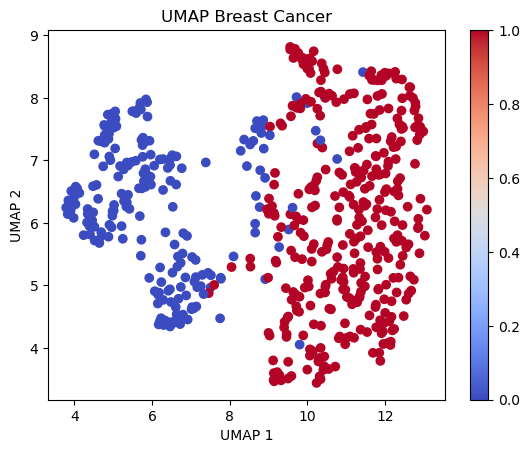

In [11]:
X_scaled = scaler.transform(X)

reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y, cmap="coolwarm")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP Breast Cancer")
plt.colorbar()
plt.show()

UMAP показал заметное разделение двух классов.